# From Domingos's 12 Lessons to a Banking Supervision Early-Warning System
### An executable, synthetic-data laboratory

**Purpose.** Consolidate the article's lessons into one reproducible machine-learning workflow for a **six-month-ahead banking distress early-warning system (EWS)**.

**Data:** fully synthetic monthly panel (30 banks × 96 months), including a deliberately constructed latent distress mechanism. No actual bank or confidential supervisory data are used.

**Outputs:** data-quality diagnostics; feature engineering; chronological train/validation/test split; logistic-regression, random-forest and gradient-boosting benchmarks; hyperparameter selection; discrimination and calibration; ensemble; threshold sensitivity; overfitting, irrelevant-feature and multiple-testing experiments; causal caution; and deployment-readiness checklist.

> **Important:** This is a teaching simulation, not a validated supervisory model. Synthetic distress labels are created from a specified statistical mechanism, not real regulatory interventions or observed bank failures. Do not interpret its metrics, coefficients or thresholds as empirical evidence about any banking system.

**Suggested environment:** Python 3.10+, JupyterLab, `numpy`, `pandas`, `scikit-learn`, `matplotlib`.

## Study map: all 12 lessons

| # | Domingos's lesson | Where demonstrated |
|---|---|---|
| 1 | Learning = Representation + Evaluation + Optimization | Pipeline and metric/model choices |
| 2 | It's Generalization That Counts | Out-of-time test set |
| 3 | Data Alone Is Not Enough | Supervisory features and model inductive bias |
| 4 | Overfitting Has Many Faces | Tree-depth, regularization, validation search |
| 5 | Intuition Fails in High Dimensions | Irrelevant features, PCA, KNN |
| 6 | Theoretical Guarantees Are Not What They Seem | Finite-class PAC bound and assumptions |
| 7 | Feature Engineering Is the Key | Lags, changes, rolling features, interactions |
| 8 | More Data Beats a Cleverer Algorithm | Learning curve |
| 9 | Learn Many Models, Not Just One | Soft-voting ensemble |
| 10 | Simplicity Does Not Imply Accuracy | Baseline vs complex model |
| 11 | Representable Does Not Imply Learnable | XOR example |
| 12 | Correlation Does Not Imply Causation | Confounding simulation |

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, confusion_matrix,
                             precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance

SEED = 42
rng = np.random.default_rng(SEED)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "| pandas:", pd.__version__)

Python: 3.13.5
NumPy: 2.3.5 | pandas: 2.2.3


## 1. Generate a realistic-looking but entirely synthetic banking panel

The simulator includes persistent bank-specific heterogeneity, macroeconomic cycles, correlated financial ratios, occasional idiosyncratic shocks, and distress labels generated from a **future six-month risk window**.

To avoid an accidental look-ahead, the distress outcome is explicitly generated from future latent monthly events, whereas all predictors available to the model are observed at the forecast origin.

**Design caveat:** the synthetic process is intentionally learnable; real supervisory outcomes have reporting delays, policy interventions, survivorship issues and label-definition problems that this simulation does not reproduce.

In [2]:
n_banks, n_months = 30, 96
dates = pd.date_range("2017-01-01", periods=n_months, freq="MS")
rows = []
bank_rng = np.random.default_rng(SEED)
bank_capital = bank_rng.normal(0, 1, n_banks)
bank_risk = bank_rng.normal(0, 1, n_banks)
bank_funding = bank_rng.normal(0, 1, n_banks)

macro_cycle = np.zeros(n_months)
for t in range(1, n_months):
    macro_cycle[t] = 0.83 * macro_cycle[t-1] + bank_rng.normal(0, 0.36)

for b in range(n_banks):
    risk_state = bank_risk[b]
    for t, date in enumerate(dates):
        risk_state = 0.76*risk_state + 0.24*bank_risk[b] + bank_rng.normal(0, 0.32)
        cycle = macro_cycle[t]
        car = np.clip(16.2 + 1.6*bank_capital[b] - 1.6*risk_state - 0.6*cycle + bank_rng.normal(0, 0.9), 4, 29)
        npl = np.clip(7.0 + 3.3*risk_state + 1.6*cycle + bank_rng.normal(0, 1.3), 0.2, 38)
        liquidity = np.clip(31 - 3.4*bank_funding[b] - 2.0*risk_state + bank_rng.normal(0, 3), 5, 65)
        roa = np.clip(1.7 - 0.55*risk_state - 0.14*npl + bank_rng.normal(0, 0.55), -9, 6)
        credit_growth = np.clip(9 + 2.5*risk_state - 1.5*cycle + bank_rng.normal(0, 4), -22, 35)
        deposit_concentration = np.clip(25 + 5*bank_funding[b] + 2*risk_state + bank_rng.normal(0, 4), 5, 75)
        rows.append((f"B{b+1:02d}", date, t, car, npl, liquidity, roa, credit_growth,
                     deposit_concentration, cycle, risk_state))
cols = ["bank_id","date","month_index","car","npl","liquidity","roa",
        "credit_growth","deposit_concentration","macro_stress","latent_risk"]
panel = pd.DataFrame(rows, columns=cols).sort_values(["bank_id","date"]).reset_index(drop=True)

# Monthly latent distress event. Risk is deliberately related to contemporaneous financial conditions.
logit = (-3.65 + 0.21*(panel["npl"]-9) - 0.24*(panel["car"]-13)
         - 0.035*(panel["liquidity"]-28) - 0.25*panel["roa"]
         + 0.30*panel["macro_stress"] + 0.22*panel["latent_risk"])
event_probability = 1/(1+np.exp(-np.clip(logit,-30,30)))
panel["monthly_event"] = bank_rng.binomial(1, event_probability)

# Outcome: at least one event in months t+1,...,t+6. No same-month event in label.
horizon = 6
def forward_event(s):
    a = s.to_numpy()
    return pd.Series([int(a[i+1:min(i+1+horizon,len(a))].max()) if i+horizon<len(a) else np.nan
                      for i in range(len(a))], index=s.index)
panel["distress_next_6m"] = panel.groupby("bank_id", group_keys=False)["monthly_event"].apply(forward_event)
print("Panel:", panel.shape, "| Bank-months with known future horizon:", panel["distress_next_6m"].notna().sum())
print("Outcome prevalence:", round(panel["distress_next_6m"].mean(), 3))
panel.head()

Panel: (2880, 13) | Bank-months with known future horizon: 2700
Outcome prevalence: 0.079


,bank_id,date,month_index,car,npl,liquidity,roa,credit_growth,deposit_concentration,macro_stress,latent_risk,monthly_event,distress_next_6m
0,B01,2017-01-01,0,12.639515,14.097386,27.351101,-0.813823,22.477387,21.133753,0.000000,2.633090,0,0.0
1,B01,2017-02-01,1,14.031086,13.839430,29.252529,-1.199578,13.043580,21.350211,0.239539,2.392524,0,0.0
2,B01,2017-03-01,2,13.245329,16.615144,32.433489,-1.525960,6.254297,20.950801,0.163362,2.280012,0,0.0
3,B01,2017-04-01,3,12.437541,12.355530,31.765446,-0.613362,8.662050,20.662118,-0.016797,1.976971,0,0.0
4,B01,2017-05-01,4,13.439731,14.378506,34.612986,-0.601279,13.099834,17.524998,-0.042640,1.861559,0,0.0


## 2. Data checks and point-in-time feature engineering

A lag is based on **prior bank observations**. The current month's ratio is treated as available at the forecast origin; in production, this assumption must be adjusted for actual regulatory submission and validation delays.

**Avoid leakage:** neither `monthly_event`, `latent_risk`, `event_probability` nor any future outcome belongs in the model feature matrix.

In [3]:
panel = panel.sort_values(["bank_id","date"]).copy()
g = panel.groupby("bank_id", sort=False)
panel["npl_change_3m"] = g["npl"].diff(3)
panel["car_change_3m"] = g["car"].diff(3)
panel["liquidity_change_3m"] = g["liquidity"].diff(3)
panel["npl_avg_3m"] = g["npl"].transform(lambda s: s.rolling(3, min_periods=3).mean())
panel["car_gap_13"] = panel["car"] - 13
panel["npl_gap_10"] = panel["npl"] - 10
panel["joint_weakness"] = ((panel["car"] < 13) & (panel["npl"] > 10)).astype(int)
panel["npl_x_car_gap"] = panel["npl_gap_10"] * (-panel["car_gap_13"])

core_features = ["car","npl","liquidity","roa","credit_growth","deposit_concentration","macro_stress"]
engineered_features = ["npl_change_3m","car_change_3m","liquidity_change_3m",
                       "npl_avg_3m","car_gap_13","npl_gap_10","joint_weakness","npl_x_car_gap"]
all_features = core_features + engineered_features
assert not set(["latent_risk","monthly_event","distress_next_6m"]).intersection(all_features)
assert not panel.duplicated(["bank_id","date"]).any()
print("Missing fraction by feature:")
print(panel[all_features].isna().mean().sort_values(ascending=False).round(3))

Missing fraction by feature:
liquidity_change_3m      0.031
car_change_3m            0.031
npl_change_3m            0.031
npl_avg_3m               0.021
car                      0.000
npl                      0.000
liquidity                0.000
macro_stress             0.000
deposit_concentration    0.000
credit_growth            0.000
roa                      0.000
car_gap_13               0.000
npl_gap_10               0.000
joint_weakness           0.000
npl_x_car_gap            0.000
dtype: float64


## 3. Chronological split with a six-month label embargo

The target for a forecast made at month *t* includes events through *t+6*. If a training observation's target window overlaps a later validation period, the model would effectively learn from events in the evaluation period.

We therefore use **non-overlapping label windows**, dropping six forecast-origin months immediately before each evaluation block.

- Train: forecast origins through month 47, with labels ending by month 53.
- Validation: forecast origins months 54–65, with labels ending by month 71.
- Test: forecast origins months 72–89, with labels ending by month 95.

All banks share the same calendar splits to reduce cross-bank leakage from common shocks. This is a **single illustrative holdout**, not a replacement for repeated rolling-origin evaluation.

In [4]:
data = panel.loc[panel["distress_next_6m"].notna()].copy()
train = data.loc[data.month_index <= 47].copy()
valid = data.loc[data.month_index.between(54, 65)].copy()
test = data.loc[data.month_index.between(72, 89)].copy()
target = "distress_next_6m"
for name, part in [("Train",train),("Validation",valid),("Test",test)]:
    print(f"{name:11s}: {len(part):4d} rows | {part.date.min().date()} to {part.date.max().date()} "
          f"| prevalence={part[target].mean():.3f}")
assert train.month_index.max()+horizon < valid.month_index.min()
assert valid.month_index.max()+horizon < test.month_index.min()
assert train[target].nunique()==2 and valid[target].nunique()==2 and test[target].nunique()==2

Train      : 1440 rows | 2017-01-01 to 2020-12-01 | prevalence=0.081
Validation :  360 rows | 2021-07-01 to 2022-06-01 | prevalence=0.042
Test       :  540 rows | 2023-01-01 to 2024-06-01 | prevalence=0.124


## 4. Define models, metrics and validation discipline

The baseline is regularized logistic regression with median imputation and scaling. Tree-based learners also receive imputation through pipelines. Imputers and scalers are fitted on **training data only**.

**Primary comparison:** PR-AUC (average precision), ROC-AUC and Brier score. We report recall and precision at a fixed threshold separately. Average precision is sensitive to event prevalence and should always be interpreted against the prevalence baseline.

Hyperparameters are selected on validation data. The test set is used once for final evaluation.

In [5]:
def linear_pipeline(C=1.0):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, max_iter=2000, random_state=SEED))
    ])

def forest_pipeline(max_depth=5, min_samples_leaf=15):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=120, max_depth=max_depth,
                                          min_samples_leaf=min_samples_leaf,
                                          random_state=SEED, n_jobs=-1))
    ])

def boost_pipeline(max_leaf_nodes=15, l2_regularization=1.0):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=100, learning_rate=0.05, max_leaf_nodes=max_leaf_nodes,
            l2_regularization=l2_regularization, random_state=SEED))
    ])

def metrics(y, p, threshold=0.5):
    pred = (np.asarray(p) >= threshold).astype(int)
    return {
        "PR_AUC": average_precision_score(y,p),
        "ROC_AUC": roc_auc_score(y,p),
        "Brier": brier_score_loss(y,p),
        "Recall": recall_score(y,pred,zero_division=0),
        "Precision": precision_score(y,pred,zero_division=0)
    }

specs = {
    "Logistic": [(dict(C=c), linear_pipeline(C=c)) for c in [0.03,0.3,3.0]],
    "RandomForest": [(dict(max_depth=d,min_samples_leaf=leaf),
                       forest_pipeline(d,leaf)) for d in [3,7] for leaf in [10,25]],
    "GradientBoosting": [(dict(max_leaf_nodes=leaves,l2_regularization=l2),
                          boost_pipeline(leaves,l2)) for leaves in [7,15] for l2 in [0.5,5.0]]
}
chosen = {}
tuning_rows = []
for family, candidates in specs.items():
    for params, model in candidates:
        model.fit(train[all_features], train[target].astype(int))
        p = model.predict_proba(valid[all_features])[:,1]
        score = metrics(valid[target].astype(int),p)
        tuning_rows.append({"family":family,"params":str(params),**score})
        if family not in chosen or score["PR_AUC"] > chosen[family]["val_PR_AUC"]:
            chosen[family] = {"model":model,"params":params,"val_PR_AUC":score["PR_AUC"]}
tuning = pd.DataFrame(tuning_rows).sort_values(["family","PR_AUC"],ascending=[True,False])
print(tuning[["family","params","PR_AUC","ROC_AUC","Brier"]].round(3).to_string(index=False))

          family                                           params  PR_AUC  ROC_AUC  Brier
GradientBoosting {'max_leaf_nodes': 15, 'l2_regularization': 0.5}   0.092    0.697  0.049
GradientBoosting  {'max_leaf_nodes': 7, 'l2_regularization': 5.0}   0.086    0.692  0.048
GradientBoosting  {'max_leaf_nodes': 7, 'l2_regularization': 0.5}   0.086    0.700  0.051
GradientBoosting {'max_leaf_nodes': 15, 'l2_regularization': 5.0}   0.085    0.691  0.050
        Logistic                                      {'C': 0.03}   0.084    0.670  0.045
        Logistic                                       {'C': 3.0}   0.083    0.677  0.047
        Logistic                                       {'C': 0.3}   0.082    0.674  0.047
    RandomForest         {'max_depth': 3, 'min_samples_leaf': 25}   0.090    0.666  0.044
    RandomForest         {'max_depth': 7, 'min_samples_leaf': 25}   0.084    0.658  0.045
    RandomForest         {'max_depth': 3, 'min_samples_leaf': 10}   0.082    0.664  0.045
    Random

## 5. Final out-of-time evaluation and a simple ensemble

The ensemble averages the probabilities from the three models selected on validation data. The equal weighting is fixed in advance rather than optimized on the test set.

Test outcome prevalence: 0.124


,PR_AUC,ROC_AUC,Brier,Recall,Precision
model,,,,,
EqualWeightEnsemble,0.438,0.798,0.093,0.045,0.75
Logistic,0.436,0.794,0.092,0.045,0.60
RandomForest,0.401,0.772,0.097,0.000,0.00
GradientBoosting,0.387,0.806,0.094,0.134,0.50


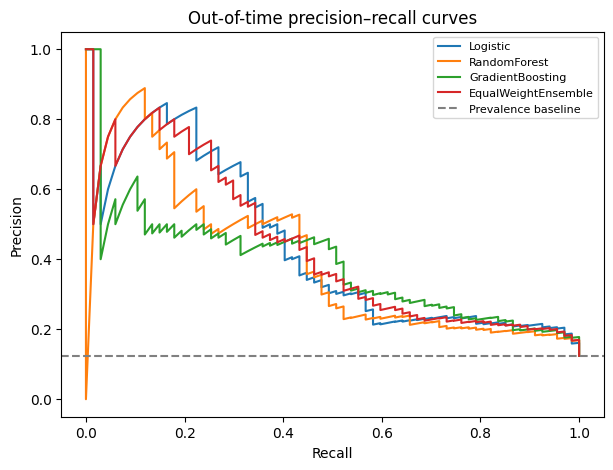

In [6]:
final_predictions = {}
for name, obj in chosen.items():
    final_predictions[name] = obj["model"].predict_proba(test[all_features])[:,1]
final_predictions["EqualWeightEnsemble"] = np.mean(
    np.column_stack(list(final_predictions.values())), axis=1)

test_metrics = pd.DataFrame([
    {"model":name,**metrics(test[target].astype(int),p)}
    for name,p in final_predictions.items()
]).set_index("model").sort_values("PR_AUC",ascending=False)
print("Test outcome prevalence:", round(test[target].mean(),3))
display(test_metrics.round(3))

fig, ax = plt.subplots(figsize=(7,5))
for name,p in final_predictions.items():
    prec, rec, _ = precision_recall_curve(test[target].astype(int),p)
    ax.plot(rec,prec,label=name)
ax.axhline(test[target].mean(),linestyle="--",color="gray",label="Prevalence baseline")
ax.set(xlabel="Recall",ylabel="Precision",title="Out-of-time precision–recall curves")
ax.legend(fontsize=8)
plt.show()

## 6. Thresholds, calibration and supervisory workload

A probability score is not itself a supervisory decision. Thresholds reflect investigation capacity, the cost of missed distress and the cost of false alerts.

Below, select a threshold **using validation data**, then report its test performance. The threshold maximizes validation F2, which emphasizes recall more than precision. This is an illustrative policy objective, not a recommendation for an actual regulator.

In [7]:
best_family = max(chosen, key=lambda k: chosen[k]["val_PR_AUC"])
best_model = chosen[best_family]["model"]
p_val = best_model.predict_proba(valid[all_features])[:,1]
p_test = best_model.predict_proba(test[all_features])[:,1]
y_val = valid[target].astype(int)
thresholds = np.arange(0.05,0.96,0.05)

def fbeta(y,p,threshold,beta=2):
    pred = (p>=threshold).astype(int)
    tp = ((pred==1)&(np.asarray(y)==1)).sum()
    fp = ((pred==1)&(np.asarray(y)==0)).sum()
    fn = ((pred==0)&(np.asarray(y)==1)).sum()
    return (1+beta**2)*tp / max((1+beta**2)*tp+beta**2*fn+fp,1)

selected_threshold = max(thresholds,key=lambda t:fbeta(y_val,p_val,t))
print("Selected model:",best_family,"| validation F2 threshold:",round(selected_threshold,2))
print("Out-of-time metrics:",{k:round(v,3) for k,v in metrics(test[target].astype(int),p_test,selected_threshold).items()})
print("Confusion matrix [[TN, FP],[FN, TP]]:")
print(confusion_matrix(test[target].astype(int),(p_test>=selected_threshold).astype(int)))

# Calibration by broad score bins (descriptive; sparse bins may be unstable).
cal = pd.DataFrame({"pred":p_test,"actual":test[target].astype(int).to_numpy()})
cal["bin"] = pd.cut(cal["pred"],bins=np.linspace(0,1,6),include_lowest=True)
print(cal.groupby("bin",observed=False).agg(
    count=("actual","size"),mean_pred=("pred","mean"),event_rate=("actual","mean")
).round(3))

Selected model: GradientBoosting | validation F2 threshold: 0.15
Out-of-time metrics: {'PR_AUC': 0.387, 'ROC_AUC': 0.806, 'Brier': 0.094, 'Recall': 0.522, 'Precision': 0.33}
Confusion matrix [[TN, FP],[FN, TP]]:
[[402  71]
 [ 32  35]]
               count  mean_pred  event_rate
bin                                        
(-0.001, 0.2]    455      0.034       0.073
(0.2, 0.4]        57      0.272       0.368
(0.4, 0.6]        23      0.506       0.478
(0.6, 0.8]         5      0.691       0.400
(0.8, 1.0]         0        NaN         NaN


## 7. Overfitting experiment: tree depth

The following experiment is **illustrative only** and uses the validation split. It must not be used to change the final model after viewing test results.

,depth,train_AP,validation_AP
0,1,0.174,0.055
1,2,0.231,0.056
2,3,0.323,0.058
3,4,0.411,0.054
4,5,0.506,0.078
5,7,0.654,0.068
6,10,0.730,0.049
7,None,0.757,0.058


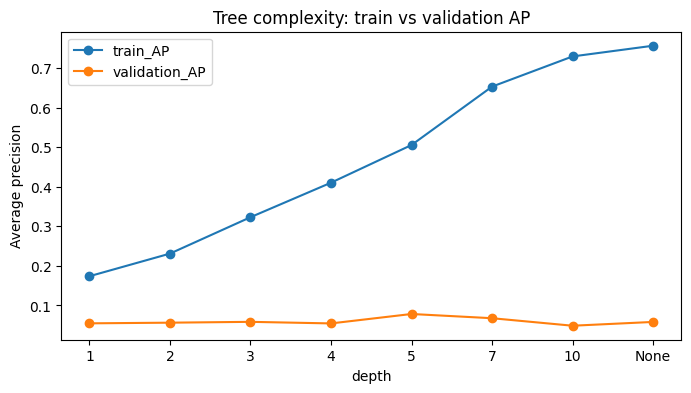

In [8]:
tree_rows = []
for depth in [1,2,3,4,5,7,10,None]:
    m = Pipeline([
        ("impute",SimpleImputer(strategy="median")),
        ("tree",DecisionTreeClassifier(max_depth=depth,min_samples_leaf=5,random_state=SEED))
    ])
    m.fit(train[all_features],train[target].astype(int))
    tree_rows.append({
        "depth":str(depth),
        "train_AP":average_precision_score(train[target],m.predict_proba(train[all_features])[:,1]),
        "validation_AP":average_precision_score(valid[target],m.predict_proba(valid[all_features])[:,1])
    })
depth_df = pd.DataFrame(tree_rows)
display(depth_df.round(3))
depth_df.set_index("depth")[["train_AP","validation_AP"]].plot(marker="o",figsize=(8,4),
                                                                title="Tree complexity: train vs validation AP")
plt.ylabel("Average precision")
plt.show()

## 8. Dimensionality experiment: relevant versus irrelevant features

Replicate the logic of Domingos's binary-feature example: the outcome depends on only two features, while 98 additional binary features are irrelevant. Compare KNN using two features versus all 100.

This is a **separate synthetic experiment**, not the supervisory distress dataset.

In [9]:
r = np.random.default_rng(SEED+1)
ntr, nte = 1000, 500
sig_tr = r.integers(0,2,(ntr,2))
sig_te = r.integers(0,2,(nte,2))
yt = sig_tr[:,0]&sig_tr[:,1]
yv = sig_te[:,0]&sig_te[:,1]
noise_tr = r.integers(0,2,(ntr,98))
noise_te = r.integers(0,2,(nte,98))
full_tr = np.column_stack([sig_tr,noise_tr])
full_te = np.column_stack([sig_te,noise_te])
for name,a,b in [("2 relevant",sig_tr,sig_te),("100 total",full_tr,full_te)]:
    m = KNeighborsClassifier(n_neighbors=5,metric="hamming")
    m.fit(a,yt)
    pred=m.predict(b)
    from sklearn.metrics import balanced_accuracy_score
    print(name,"accuracy",round((pred==yv).mean(),3),
          "balanced accuracy",round(balanced_accuracy_score(yv,pred),3))

2 relevant accuracy 1.0 balanced accuracy 1.0
100 total accuracy 0.748 balanced accuracy 0.608


## 9. PCA: reduce correlated features without peeking at evaluation data

PCA captures variation in predictors, not necessarily variation relevant to distress. Fit the imputer, scaler and PCA on training observations only, and assess explained variance as a descriptive diagnostic.

8 of 15 principal components explain at least 90% of training feature variance.


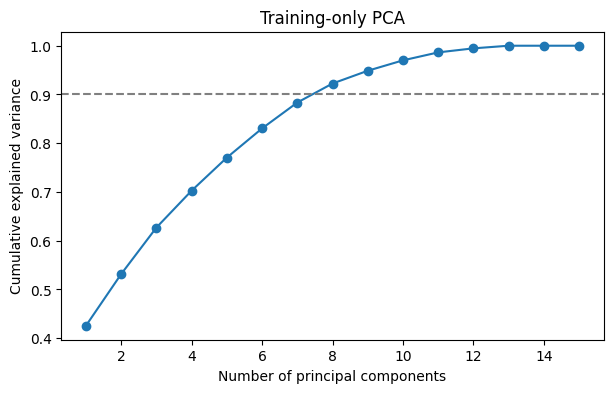

In [10]:
pca_pipe = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("scale",StandardScaler()),
    ("pca",PCA())
])
pca_pipe.fit(train[all_features])
cumvar=np.cumsum(pca_pipe.named_steps["pca"].explained_variance_ratio_)
k90=int(np.searchsorted(cumvar,0.90)+1)
print(f"{k90} of {len(all_features)} principal components explain at least 90% of training feature variance.")
plt.figure(figsize=(7,4))
plt.plot(range(1,len(cumvar)+1),cumvar,marker="o")
plt.axhline(0.90,linestyle="--",color="gray")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Training-only PCA")
plt.show()

## 10. More data: chronological learning curve

Train the fixed logistic baseline on progressively longer **early** training windows, then score on the same later validation period. This avoids randomly shuffling future observations into the past.

,train_months,train_rows,validation_AP
0,18,540,0.084
1,24,720,0.079
2,30,900,0.077
3,36,1080,0.080
4,42,1260,0.079
5,48,1440,0.082


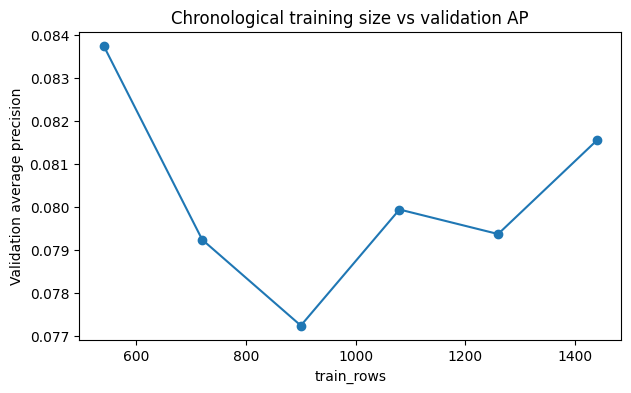

In [11]:
learning_rows=[]
for last_month in [17,23,29,35,41,47]:
    subset=train.loc[train.month_index<=last_month]
    if subset[target].nunique()<2:
        continue
    m=linear_pipeline(C=0.3)
    m.fit(subset[all_features],subset[target].astype(int))
    p=m.predict_proba(valid[all_features])[:,1]
    learning_rows.append({"train_months":last_month+1,"train_rows":len(subset),
                          "validation_AP":average_precision_score(valid[target],p)})
learning=pd.DataFrame(learning_rows)
display(learning.round(3))
learning.plot(x="train_rows",y="validation_AP",marker="o",legend=False,figsize=(7,4),
              title="Chronological training size vs validation AP")
plt.ylabel("Validation average precision")
plt.show()

## 11. Multiple testing and false discoveries

Under independent null tests with significance level α, the expected number of false positives is `m × α`; the chance of at least one is `1-(1-α)^m`. Independence is required for that exact probability formula.

This demonstrates the danger of repeatedly screening hundreds of candidate indicators.

In [12]:
alpha=0.05
m_values=[1,10,20,50,100,200]
multiple=pd.DataFrame({
    "tests":m_values,
    "expected_false_positives":[m*alpha for m in m_values],
    "prob_at_least_one":[1-(1-alpha)**m for m in m_values]
})
display(multiple.round(4))

,tests,expected_false_positives,prob_at_least_one
0,1,0.05,0.0500
1,10,0.50,0.4013
2,20,1.00,0.6415
3,50,2.50,0.9231
4,100,5.00,0.9941
5,200,10.00,1.0000


## 12. PAC bounds, expressiveness and causation

**PAC:** A finite-hypothesis consistent-learning bound is conditional on iid sampling and a realizable setting. A monthly bank panel does not generally satisfy the iid assumption.

**Representability:** XOR is not linearly separable, but a depth-2 decision tree can represent it.

**Causality:** A predictive relationship can be induced by a common cause. The following synthetic simulation makes two variables correlated without specifying a direct causal link between them.

In [13]:
def finite_H_bound(H,epsilon=0.05,delta=0.05):
    return int(np.ceil((np.log(H)+np.log(1/delta))/epsilon))
print("Finite-H sufficient bound:",finite_H_bound(1000))

xor_X=np.array([[0,0],[0,1],[1,0],[1,1]])
xor_y=np.array([0,1,1,0])
for name,model in [("Linear logistic",LogisticRegression()),
                   ("Decision tree",DecisionTreeClassifier(max_depth=2,random_state=SEED))]:
    model.fit(xor_X,xor_y)
    print(name,"XOR training accuracy:",round(model.score(xor_X,xor_y),3))

r=np.random.default_rng(SEED+2)
recession=r.normal(size=1500)
npl_proxy=3*recession+r.normal(size=1500)
distress_proxy=2*recession+r.normal(size=1500)
print("Correlation between NPL and distress proxies:",
      round(np.corrcoef(npl_proxy,distress_proxy)[0,1],3))
print("This association was created by a common cause; it does not estimate an intervention effect.")

Finite-H sufficient bound: 199
Linear logistic XOR training accuracy: 0.5
Decision tree XOR training accuracy: 1.0
Correlation between NPL and distress proxies: 0.841
This association was created by a common cause; it does not estimate an intervention effect.


## 13. Interpretability, stability and deployment-readiness

Permutation importance here is computed on **validation** data for the selected model and a PR-AUC scoring objective. Correlated features can share importance; scores are predictive diagnostics, not causal effects.

For real supervision, review performance by bank type, size, macro regime, event horizon and time; test drift, missingness, alert workload, model calibration and override governance. The current synthetic example is **not deployment ready**.

In [14]:
importance = permutation_importance(
    best_model,valid[all_features],valid[target].astype(int),
    scoring="average_precision",n_repeats=5,random_state=SEED,n_jobs=1
)
importance_df=pd.DataFrame({
    "feature":all_features,
    "mean_drop_in_AP":importance.importances_mean,
    "std":importance.importances_std
}).sort_values("mean_drop_in_AP",ascending=False)
display(importance_df.head(12).round(4))

,feature,mean_drop_in_AP,std
10,npl_avg_3m,0.0152,0.0145
0,car,0.0130,0.0169
6,macro_stress,0.0114,0.0028
5,deposit_concentration,0.0109,0.0050
2,liquidity,0.0079,0.0065
7,npl_change_3m,0.0070,0.0068
12,npl_gap_10,0.0000,0.0000
13,joint_weakness,0.0000,0.0000
11,car_gap_13,0.0000,0.0000
9,liquidity_change_3m,-0.0019,0.0075


## 14. Export research outputs

Exports are optional and saved to a local `ews_outputs` directory. The output includes only synthetic results.

Before replacing synthetic data with real supervisory records, **do not** export raw observations or identifiers to an unsecured directory. Obtain appropriate data-use approval and apply institutional information-security requirements.

In [15]:
from pathlib import Path
out=Path("ews_outputs")
out.mkdir(exist_ok=True)
test_metrics.to_csv(out/"synthetic_test_metrics.csv")
tuning.to_csv(out/"synthetic_validation_tuning.csv",index=False)
importance_df.to_csv(out/"synthetic_feature_importance.csv",index=False)
print("Saved three synthetic results files to:",out.resolve())

Saved three synthetic results files to: /mnt/data/ews_outputs


## 15. Research protocol for the transition to actual supervisory data

**Phase A — Data governance.** Confirm legal authority, confidentiality controls, reporting definitions, revisions, missingness and permitted processing environments.

**Phase B — Outcome specification.** Define distress precisely (e.g., supervisory intervention, capital breach, liquidity stress, resolution), horizon, observation availability and whether the event is a stock or new onset. Avoid treating overlapping six-month labels as independent events.

**Phase C — Point-in-time panel.** Establish report-as-of dates, publication delays, vintage data, bank identifiers, mergers, failures and survivorship handling. Preserve the forecast-origin timestamp.

**Phase D — Model design.** Pre-register candidate indicators, baseline models, feature-engineering rules, tuning budget and primary metric. Consider bank- and time-clustered uncertainty and rare-event confidence intervals.

**Phase E — Validation.** Use multiple rolling-origin evaluations with label embargoes, crisis-period stress tests, calibration, PR-AUC, recall, precision and alert workload. Ensure all preprocessing, feature selection and tuning occur inside the appropriate training/validation windows.

**Phase F — Governance.** Document assumptions, limitations, explainability, human review, drift monitoring, retraining triggers, version control and supervisory escalation procedures.

### Suggested capstone research question

> Do domain-informed engineered supervisory indicators and flexible machine-learning models improve out-of-time six-month-ahead banking distress prediction relative to a parsimonious logistic regression benchmark?

### Discussion prompts
1. Why is a random train/test split risky in a monthly banking panel?
2. Why can PR-AUC be more informative than accuracy when distress is rare?
3. What changes if distress labels overlap across six forecast months?
4. When does an ensemble justify its added complexity?
5. Why does feature importance not establish causality?
6. Which real-world data restrictions would prevent immediate deployment?

**Primary reading:** Pedro Domingos (2012), *A Few Useful Things to Know About Machine Learning*, *Communications of the ACM*, 55(10), 78–87. This notebook is an original teaching application inspired by its 12 lessons; its synthetic examples and workflow are not empirical results from the article.